# Open-Fret: from MIDI to tablature, plotted inline

Self-contained demo: install deps, download the released checkpoint from
Hugging Face, transcribe a hand-written MIDI phrase with the repo's
anchored decoder, and **plot** the input (piano roll) plus the predicted
tab (string/fret diagram) with matplotlib — no CDN, no JavaScript needed
for the plots. An interactive AlphaTab viewer cell is included at the end
(its JS *and* soundfont are embedded from the repo, so it also works
offline once the notebook kernel has the packages).

Needs: Python 3.10+, `git`, internet for the one-time downloads. If you
manage environments with `uv`, point your kernel at one first:
`uv venv && uv pip install torch transformers huggingface_hub pretty_midi matplotlib`
(the setup cell below otherwise installs to the user site when it detects
a bare system interpreter, never touching system packages).

Provenance: the input below is a hand-written 8-note phrase, no corpus
material. The tab is a real model prediction through the repo's anchored
decoder (one fingering slot per input attack).

In [1]:
import importlib, subprocess, sys
import sysconfig

print("interpreter:", sys.executable)
IN_VENV = sys.prefix != sys.base_prefix
print("venv/conda env active:", IN_VENV)

def ensure(pkg, pip_name=None, extra_args=()):
    try:
        importlib.import_module(pkg)
        print(f"{pkg}: present")
        return
    except ImportError:
        pass
    # Never escalate: on a bare system interpreter (no venv) install to
    # the user site instead of touching the system environment; inside an
    # env (venv/conda/uv-managed kernel) install normally.
    target = [] if IN_VENV else ["--user"]
    cmd = [sys.executable, "-m", "pip", "install", "-q", *target,
           f"{(pip_name or pkg)}", *extra_args]
    print("installing:", " ".join(cmd))
    try:
        subprocess.check_call(cmd)
    except Exception as e:
        raise SystemExit(
            f"Could not install {pkg} ({e}). If you manage envs with uv, "
            "create/select one first, e.g.:\n"
            "  uv venv && uv pip install torch transformers "
            "huggingface_hub pretty_midi matplotlib\n"
            "then pick its kernel in Jupyter (or `uv run --with jupyter "
            "jupyter lab`).") from e

ensure("matplotlib")
ensure("pretty_midi")
ensure("huggingface_hub")
ensure("transformers")
try:
    import torch  # noqa: F401
    print("torch: present")
except ImportError:
    # CPU wheel is plenty for this 14 MB model; CUDA users can
    # `pip install torch` instead.
    ensure("torch", extra_args=("--index-url",
                                  "https://download.pytorch.org/whl/cpu",))

interpreter: /tmp/opencode/venv_cu/bin/python
venv/conda env active: True
matplotlib: present
pretty_midi: present
huggingface_hub: present


/tmp/opencode/venv_cu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers: present


torch: present


In [2]:
import os, subprocess, sys
from pathlib import Path

def find_repo(modpath="open_fret/viewer.py"):
    try:
        import open_fret  # noqa: F401
        return Path(open_fret.__file__).resolve().parents[1]
    except ImportError:
        pass
    cands = []
    for entry in sys.path:
        if entry:
            cands += [Path(entry), Path(entry).parent]
    here = Path.cwd().resolve()
    cands += [here, *here.parents]
    for cand in cands:
        if (cand / modpath).exists():
            return cand
    return None

REPO = find_repo()
if REPO is None:
    # Fresh machine / Colab: shallow-clone the verified branch.
    if not Path("open-fret").exists():
        subprocess.check_call(["git", "clone", "--depth", "1",
                               "--branch", "first-working-training-loop",
                               "https://github.com/mylonasc/open-fret.git"])
    REPO = Path("open-fret").resolve()
    print("cloned repo to:", REPO)
else:
    print("using repo at:", REPO)
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / "scripts"))
import open_fret  # noqa: E402,F401

assert (REPO / "open_fret" / "viewer.py").exists(), REPO

using repo at: /home/charilaos/Workspace/open-fret


In [3]:
from huggingface_hub import snapshot_download

MODEL_DIR = snapshot_download("mylonasc/open-fret-tab")
print("model dir:", MODEL_DIR)
print(sorted(os.listdir(MODEL_DIR)))

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Fetching 8 files: 100%|██████████| 8/8 [00:00<00:00, 3153.61it/s]

model dir: /home/charilaos/.cache/huggingface/hub/models--mylonasc--open-fret-tab/snapshots/49f6e88d71334564d5a5b16017a746d93904a4cd
['.gitattributes', 'README.md', 'config.json', 'generation_config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_info.json']


In [4]:
import pretty_midi

# E-minor-pentatonic lick + closing dyad. Ticks at 480 PPQ, 100 BPM.
phrase = [(0, 480, 64), (480, 960, 67), (960, 1440, 69), (1440, 1920, 71),
          (1920, 2400, 74), (2400, 2880, 76),
          (2880, 3360, 67), (2880, 3360, 64)]
SEC_PER_TICK = 60 / (100 * 480)
pm = pretty_midi.PrettyMIDI(initial_tempo=100)
inst = pretty_midi.Instrument(
    program=pretty_midi.instrument_name_to_program("Acoustic Guitar (nylon)"))
for start, end, pitch in phrase:
    inst.notes.append(pretty_midi.Note(velocity=100, pitch=pitch,
                                        start=start * SEC_PER_TICK,
                                        end=end * SEC_PER_TICK))
pm.instruments.append(inst)
MIDI_PATH = "open-fret-demo.mid"
pm.write(MIDI_PATH)
print(f"wrote {MIDI_PATH}: {len(phrase)} notes,",
      f"pitches {sorted({p for _, _, p in phrase})}")

wrote open-fret-demo.mid: 8 notes, pitches [64, 67, 69, 71, 74, 76]


In [5]:
from inference import run_inference

result = run_inference(MIDI_PATH, MODEL_DIR,
                        deterministic=True, return_report=True)
pred = result["corrected_tokens"]
print("predicted TAB tokens:", " ".join(pred))
print("corrections:", result["correction"]["refingered"], "refingered,",
      result["correction"]["inserted"], "inserted,",
      result["correction"]["dropped_extra"], "dropped")

Using device: cuda


Loading weights:   0%|          | 0/68 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 68/68 [00:00<00:00, 18189.58it/s]

/tmp/opencode/venv_cu/lib/python3.12/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


predicted TAB tokens: TAB_1_0 TS_480 TAB_2_8 TS_480 TAB_2_10 TS_480 TAB_2_12 TS_480 TAB_1_10 TS_480 TAB_1_12 TS_480 TAB_3_9 TAB_2_8 TS_480
corrections: 0 refingered, 0 inserted, 0 dropped


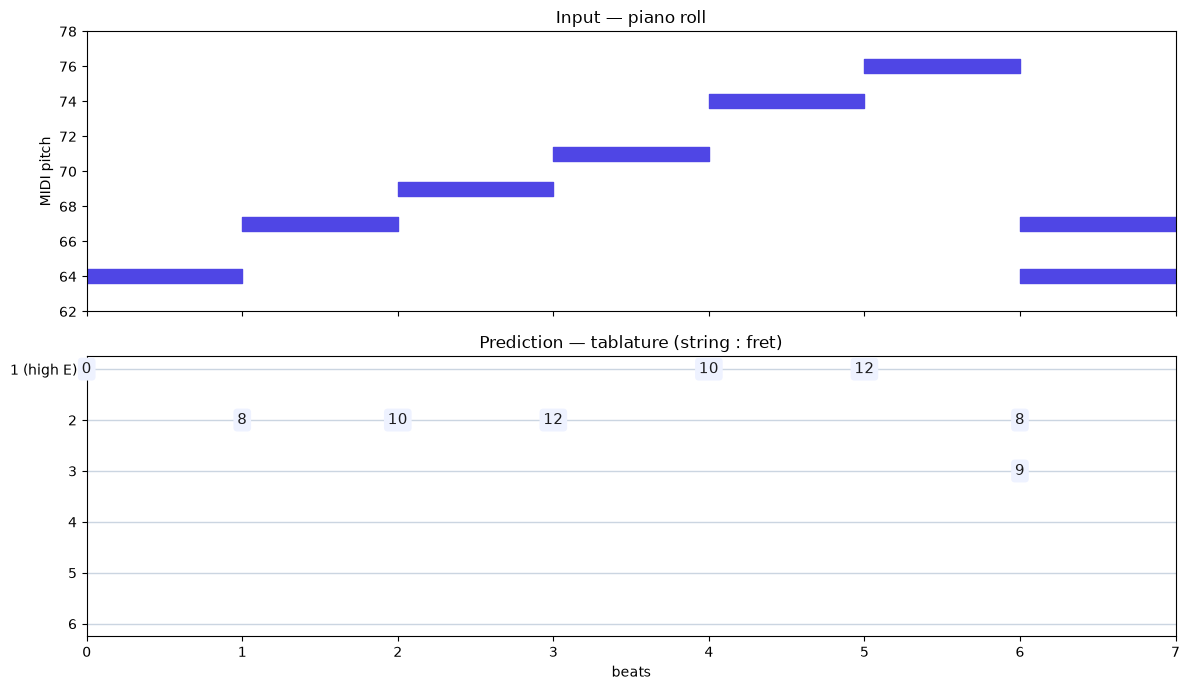

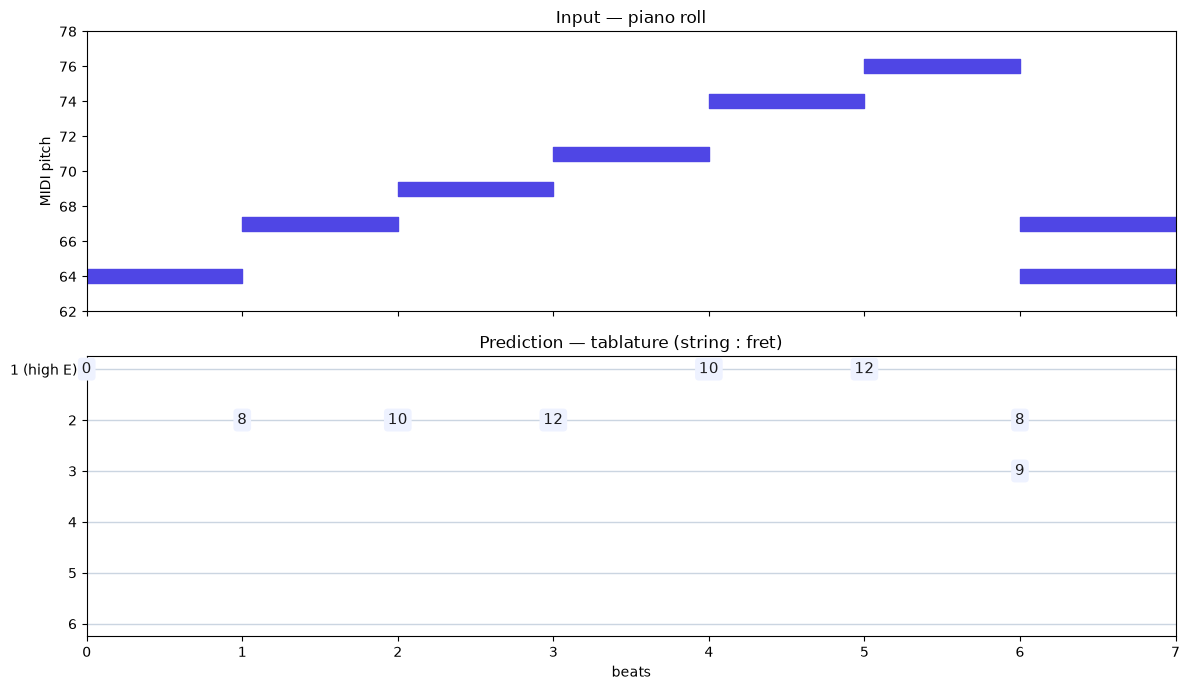

In [6]:
import matplotlib.pyplot as plt

from open_fret.events import tab_attacks
from open_fret.midi_io import midi_file_to_tokens
from open_fret.viewer import midi_tokens_to_notes

input_tokens = midi_file_to_tokens(MIDI_PATH)
in_notes = midi_tokens_to_notes(input_tokens)
tab_notes = tab_attacks(pred)
to_beats = lambda tick: tick / 480
end_beats = max(to_beats(n["end"]) for n in in_notes)

fig, (ax_roll, ax_tab) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for n in in_notes:
    ax_roll.broken_barh([(to_beats(n["start"]),
                           to_beats(n["end"]) - to_beats(n["start"]))],
                          (n["pitch"] - 0.4, 0.8), color="#4f46e5")
ax_roll.set_ylabel("MIDI pitch")
ax_roll.set_title("Input — piano roll")
ax_roll.set_ylim(min(n["pitch"] for n in in_notes) - 2,
                  max(n["pitch"] for n in in_notes) + 2)
for string in range(1, 7):
    ax_tab.axhline(7 - string, color="#cbd5e1", linewidth=1)
for n in tab_notes:
    ax_tab.text(to_beats(n["start"]), 7 - n["string"], str(n["fret"]),
                ha="center", va="center", fontsize=11, color="#1c1c1e",
                bbox=dict(boxstyle="round,pad=0.25", fc="#eef2ff", ec="none"))
ax_tab.set_yticks([6, 5, 4, 3, 2, 1])
ax_tab.set_yticklabels(["1 (high E)", "2", "3", "4", "5", "6"])
ax_tab.set_xlabel("beats")
ax_tab.set_title("Prediction — tablature (string : fret)")
ax_tab.set_xlim(0, end_beats)
fig.tight_layout()
fig  # inline plot: no CDN or JavaScript involved

In [7]:
from open_fret.viewer import build_view_bundle, show

bundle = build_view_bundle(midi_path=MIDI_PATH, tab_tokens=pred,
                             title="Notebook demo — E-minor lick (model prediction)",
                             tempo=100)
print("bundle:", bundle["meta"]["n_input_notes"], "input notes,"
      , len(bundle["tab_tokens"]), "tab tokens")
show(bundle, inline_deps=True)  # interactive score+tab, JS+soundfont embedded (works offline)

bundle: 8 input notes, 15 tab tokens


In [8]:
import re
tuning = [64, 59, 55, 50, 45, 40]  # standard, high string first
input_pitches = {p for _, _, p in phrase}
tab = [t for t in pred if t.startswith("TAB_")]
assert tab, "prediction contains no TAB attacks"
bad = []
for t in tab:
    _, s, f = t.split("_")[:3]
    if tuning[int(s) - 1] + int(f) not in input_pitches:
        bad.append(t)
assert not bad, f"pitches outside the input: {bad}"
print(f"OK: {len(tab)} TAB attacks, every pitch present in the input {sorted(input_pitches)}")

OK: 8 TAB attacks, every pitch present in the input [64, 67, 69, 71, 74, 76]
